<a href="https://colab.research.google.com/github/Jack3690/pydol/blob/main/notebooks/Resolved_Stellar_Populations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
!pip install  "pydol[jwst] @ git+https://github.com/Jack3690/pydol" -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [29]:
from pydol.photometry.scripts.gloess import gloess
from pydol.photometry.scripts.catalog_filter import box, ellipse, polygon
from pydol.photometry.scripts.cmdtools import gen_CMD, gen_CMD_ycut, gen_CMD_xcut, running_avg

from astropy.io import fits
from astropy.wcs import WCS
from astropy.table import Table, join, hstack, vstack
from astropy.visualization import simple_norm
from astropy.coordinates import angular_separation, SkyCoord
from astropy.modeling import models, fitting
from astropy.stats import sigma_clipped_stats
import astropy.units as u
from astropy.stats.biweight import biweight_location, biweight_midvariance,biweight_scale

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.ticker import (MultipleLocator, AutoLocator, AutoMinorLocator)
from matplotlib.colors import ListedColormap

import json
import shapely

The **interstellar extinction law** describes how dust and gas in the interstellar medium absorb and scatter starlight, causing a reduction in its apparent brightness and a change in its observed color. This effect depends on wavelength: blue and ultraviolet light generally experience greater extinction than red and infrared light.

Extinction is quantified by $A_\lambda$, expressed in magnitudes, and its wavelength dependence is described by an extinction curve. An important parameter is $R_V=A_V/E(B-V)$, which characterizes the shape of the extinction curve and provides information about the properties and size distribution of interstellar dust grains.

The extinction law is essential in astronomy for correcting observations for the effects of dust and accurately determining the intrinsic properties of stars and galaxies.


**Milky Way foreground extinction** refers to the absorption and scattering of light from distant astronomical objects by dust and gas located between the observer and the target object within our own Galaxy, the Milky Way. This dust reduces the observed brightness and makes objects appear redder, an effect known as interstellar reddening.

Foreground extinction is commonly quantified using the color excess $E(B-V)$ and visual extinction $A_V$, related through:
$
A_V = R_V \times E(B-V)
$

where $R_V$ is typically assumed to be approximately 3.1 for the diffuse interstellar medium of the Milky Way.

Correcting for Milky Way foreground extinction is an essential step in astronomical data analysis, as it allows us to recover the intrinsic brightness and colors of distant stars and galaxies before studying their physical properties.

In [30]:
Av_dict = {
            'f275w': 2.02499,
            'f336w': 1.67536,
            'f435w': 1.33879,
            'f555w': 1.03065,
            'f814w': 0.59696,

            'f090w': 0.583,
            'f115w': 0.419,
            'f150w': 0.287,
            'f200w': 0.195,
            'f335m': 0.103,

            'f438w': 1.34148,
            'f606w': 0.90941,
            'f814w': 0.59845
          }


The distance modulus is a measure of the distance to an astronomical object, expressed as the difference between its apparent magnitude $(m$) and absolute magnitude $(M)$. It describes how much fainter an object appears due to its distance from the observer.

The distance modulus is defined as:
$
\mu = m-M = 5\log_{10}(d)-5
$

where $d$ is the distance to the object in parsecs (pc).

When accounting for interstellar extinction, the relation becomes:
$
\mu = m-M-A_\lambda
$

where $A_\lambda$ is the extinction in the corresponding photometric band.

The distance modulus is widely used in astronomy to determine distances to stars and galaxies, particularly through standard candles such as Cepheid variables and the Tip of the Red Giant Branch (TRGB).

In [31]:
regions_gal = {
            'wlm' : {'ra'   : 0.492356,
                       'dec'  : -15.461081,
                        'dismod' : 24.94,
                        'Av': 0.104},

             'leop' :  {'ra'   : 155.437083,
                       'dec'  : 18.089444,
                        'dismod' : 26.05,
                        'Av': 0.071},

            'ngc628' : {'ra'   : 24.1738983,
                       'dec'  : 15.7836543,
                        'dismod' : 29.81,
                        'Av': 0.19,
                        'inc': 9,
                       'PA' : 21},
            'm82'   : {'ra'   : 148.9622246,
                       'dec'  :  69.6784222,
                        'dismod' : 27.79,
                        'Av': 0.429},

            'm51' :  {'ra'   : 202.4696435,
                      'dec'  : 47.1952141,
                      'dismod' : 29.4,
                       'Av': 0.09331,
                     'inc': 20.3,
                     'PA' : 12},

            'm83' :   {'ra'   : 204.2536827 ,
                       'dec'  : -29.8655432,
                       'dismod' : 28.26,
                       'Av': 0.18166,
                       'inc': 20.3,
                       'PA': 225},

            'ngc4449' : {'ra' : 187.046349,
                         'dec' :44.093666,
                         'dismod' : 27.91,
                         'Av': 0.05208,
                         'inc' : 45,
                         'PA' : 45},

             'ngc4490': {'ra' : 187.6508752,
                         'dec' :  41.6447085,
                         'dismod' : 29.66,
                         'ang': 290,
                         'a' : 130,
                         'b' : 85,
                         'Av': 0.0578,
                         'inc' : 65,
                         'PA' : 115},

             'ngc4485': {'ra' : 187.6307169,
                         'dec' :  41.6998728,
                         'dismod' : 29.66,
                         'ang': 0,
                         'a' : 50,
                         'b' : 50,
                         'Av': 0.0578,
                        'inc' : 44.6,
                        'PA' : -14.3},

             'ngc4258' : {'ra' : 184.74521832975805,
                         'dec' : 47.365,
                         'dismod' : 29.397,
                         'ang': 0,
                         'a' : 50,
                         'b' : 50,
                         'Av':  0.045},
            }

# **Step 1: Load Data**

Make a folder named rsp_jwst_school in your Google drive

Copy the following files

  a) cmd_jwst_master.csv

  b) JWST photometry catalog (i.e. NGC628_f115w_f150w_f200w_photometry.fits)

In [32]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [33]:
cd /content/drive/MyDrive/rsp_jwst_school

/content/drive/MyDrive/rsp_jwst_school


In [34]:
df_cmd_jwst = pd.read_csv("cmd_jwst_master.csv")

# **Step 2: Generate Color-Magnitude Diagrams (CMDs)**

Below we generate JWST/NIRCam using PyDOL.

Read the documentation for gen_CMD: https://pydol.readthedocs.io/en/latest/pydol.photometry.html#module-pydol.photometry.scripts.cmdtools

/usr/local/lib/python3.13/dist-packages/pydol/photometry/scripts/cmdtools.py:443: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/usr/local/lib/python3.13/dist-packages/pydol/photometry/scripts/cmdtools.py:443: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/events.py:89: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


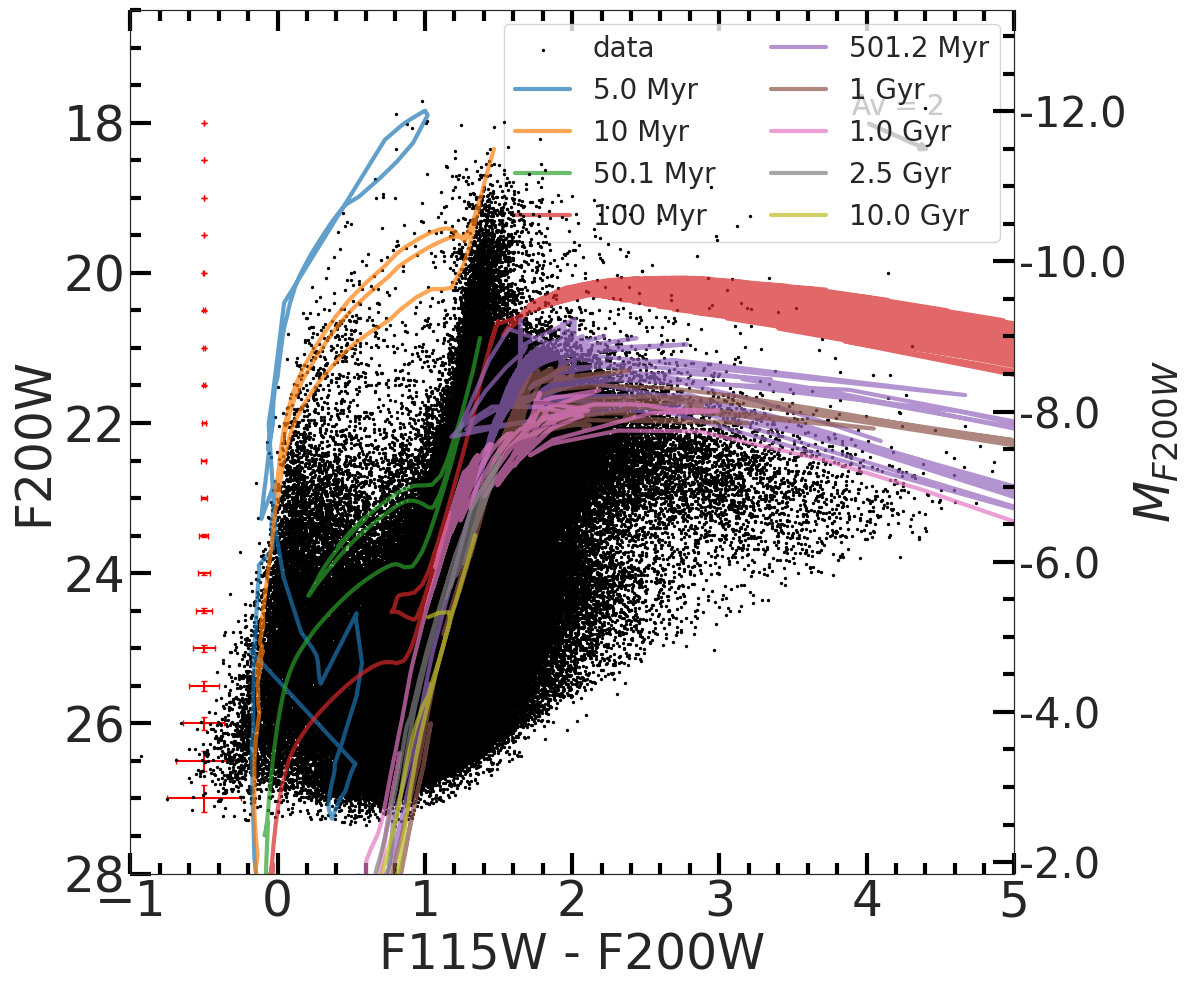

/usr/local/lib/python3.13/dist-packages/pydol/photometry/scripts/cmdtools.py:443: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/events.py:89: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


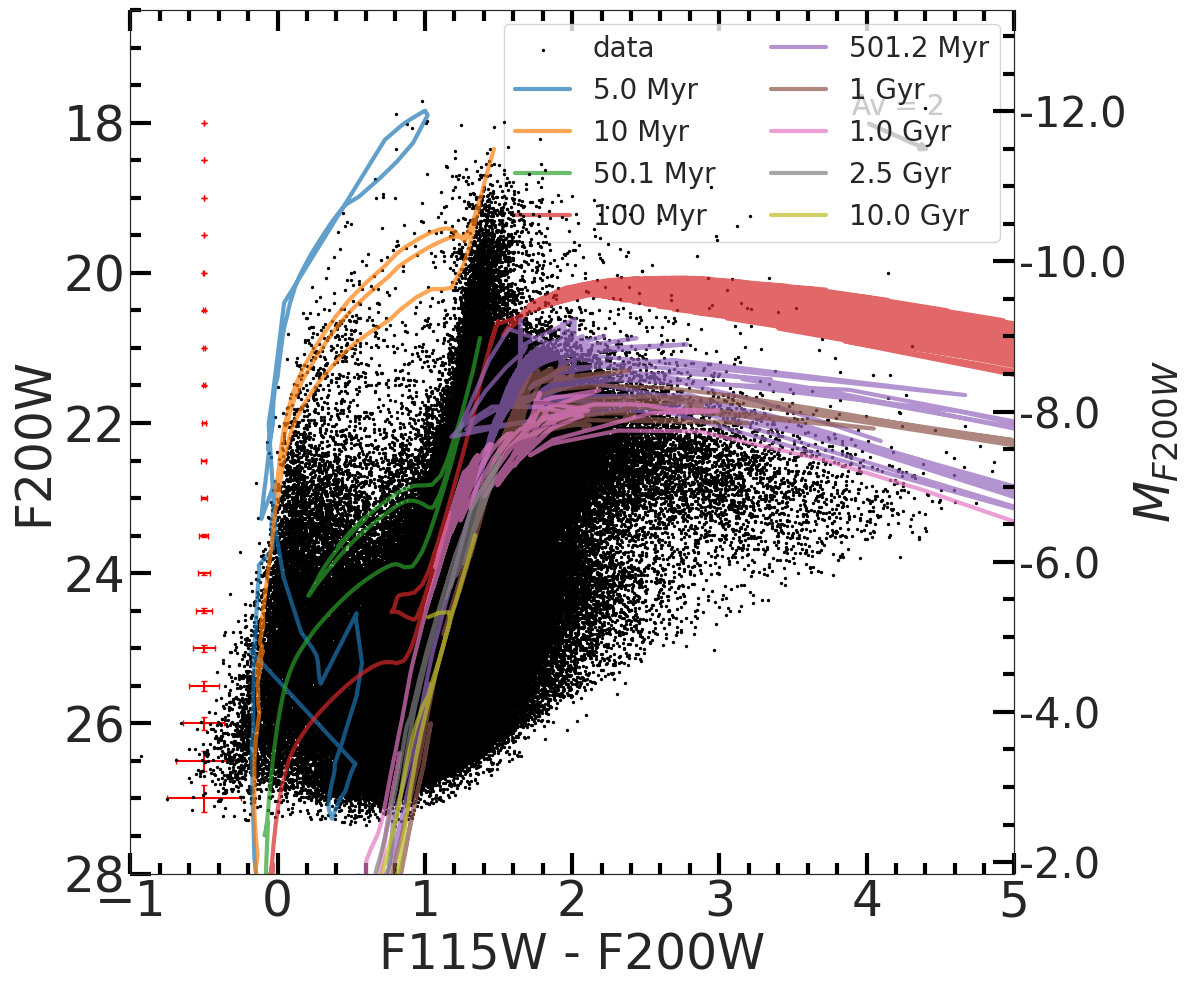

In [42]:
# Change the filename here to change photometry file
tab = Table.read('NGC628_f115w_f150w_f200w_photometry.fits')

fig, ax = plt.subplots(figsize=(12,10))
ra_cen  = regions_gal['ngc628']['ra'] # change the galaxy name here
dec_cen = regions_gal['ngc628']['dec']# change the galaxy name here

filters = {'filt1':'f115w',
           'filt2':'f200w',
           'filt3':'f200w'}

positions = {'ra_col' : 'ra',
             'dec_col': 'dec',
             'ra_cen' : ra_cen,
             'dec_cen': dec_cen}

region = {'r_in':0,
          'r_out': 2000,
          'spatial_filter': 'circle'}

extinction = {'Av'  : regions_gal['ngc628']['Av'], # change the galaxy name here
              'Av_x': 4,
              'Av_y': 18,
              'Av_' : 2}

axis_limits= {'xlims': [-1, 5],
              'ylims': [16.5, 28]}

isochrone_params={'met': [0.02],
                  'label_min': 0,
                  'label_max': 8,
                  'ages': [6.7, 7, 7.7, 8, 8.7,9]}

error_settings = {'ref_xpos': -0.5,
                  'mag_err_lim':0.2}

plot_settings = {'s':2, 'legend.ncols':2, 'alpha':0.7, 'lw':3}


fig,ax, tab1 = gen_CMD(tab,
                      df_cmd_jwst,
                      filters,
                      positions,
                      region,
                      extinction,
                      regions_gal['ngc628']['dismod'], # change the galaxy name here
                      axis_limits,
                      isochrone_params,
                      plot_settings=plot_settings,
                      error_settings=error_settings,
                      other_settings={'ab_dist': False, 'skip_data': False},
                      fig=fig, ax=ax)

isochrone_params['ages'] = [9.0, 9.4, 10.]
isochrone_params['met'] = [0.002]

fig,ax, tab1 = gen_CMD(tab,
                      df_cmd_jwst,
                      filters,
                      positions,
                      region,
                      extinction,
                      regions_gal['ngc628']['dismod'], # change the galaxy name here
                      axis_limits,
                      isochrone_params,
                      plot_settings=plot_settings,
                      error_settings=error_settings,
                      other_settings={'ab_dist': True, 'skip_data': True},
                      fig=fig, ax=ax)


# **Step 3: Spatial distribution of resolved stars**

DOLPHOT by default provides coordinates of stars in pixel coordinates (x,y). We convert it to world coordinates (RA, Dec) using reference image utilized for DOLPHOT photometry.

(np.float64(-571.066),
 np.float64(12206.446),
 np.float64(-220.73100000000005),
 np.float64(4825.651000000001))

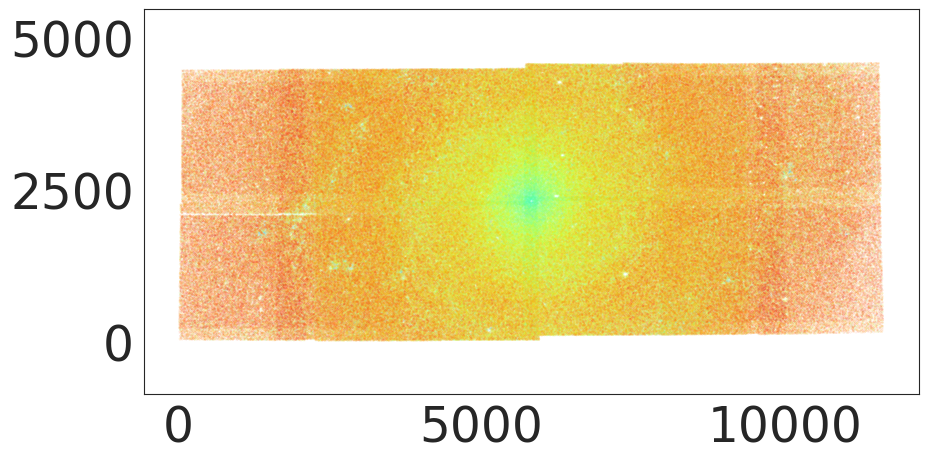

In [43]:
x = tab1['x']
y = tab1['y']
c = tab1['mag_vega_F200W']
plt.figure(figsize=(10,5))
plt.scatter(x,y, s=0.001, c=c, cmap='jet', )
plt.axis('equal')

# **Step 4: Segmenting CMD based on evolutionary phases**

With guidance from PARSEC isochrones, we segment the CMD into following evolutionary phases

1) RSG: Red Supergiant

2) BSG: Blue Supergiant

3) YSG: Yellow Supergiant

4) RRSG: Red Red Supergiant. RSGs with high reddening due to circumstellar dust.

5) YMS: Young Massive Stars. Stars more than 20 Msol

6) TRGB: Tip of the Red Giant Branch

In [37]:
trgb_box = np.array([[ 1.22, -5.11],
                   [ 1.14, -4.71],
                   [ 1.34, -4.45],
                   [ 1.44, -4.88]])

rsg_box = np.array([[  1.06,  -7.39],
                   [  1.36,  -7.39],
                   [  1.56,  -8.7 ],
                   [  1.56, -10.43],
                   [  1.23, -10.19]])

rrsg_box = np.array([[  1.56,  -8.7 ],
                   [  1.56, -10.43],
                   [  4.87, -10.61],
                   [  4.82,  -4.9 ]])

ysg_box = np.array([[  1.06,  -7.39],
                   [  1.23, -10.19],
                   [  0.32,  -9.03],
                   [  0.51,  -7.03]])

bsg_box = np.array([[ 0.51, -7.03],
                   [ 0.32, -9.03],
                   [-0.13, -8.17],
                   [-0.21, -6.1 ]])

yms_box = np.array([[  1.23, -10.19],
                   [  0.32,  -9.03],
                   [ -0.13,  -8.17],
                   [  0.16, -11.33],
                   [  1.22, -11.87],
                   [  1.6 , -11.94],
                   [  1.56, -10.42]])

In [38]:
gal = 'ngc628'
col_diff = (Av_dict['f115w'] - Av_dict['f200w'])*regions_gal[gal]['Av']
mag_diff  = regions_gal[gal]['dismod'] + (Av_dict['f115w'])*regions_gal[gal]['Av']

m_51_corr = np.array([col_diff, mag_diff])

trgb_polygon_m51 = shapely.Polygon(trgb_box + m_51_corr)
rsg_polygon_m51  = shapely.Polygon(rsg_box + m_51_corr)
rrsg_polygon_m51 = shapely.Polygon(rrsg_box + m_51_corr)
ysg_polygon_m51  = shapely.Polygon(ysg_box + m_51_corr)
bsg_polygon_m51  = shapely.Polygon(bsg_box + m_51_corr)
yms_polygon_m51  = shapely.Polygon(yms_box + m_51_corr)


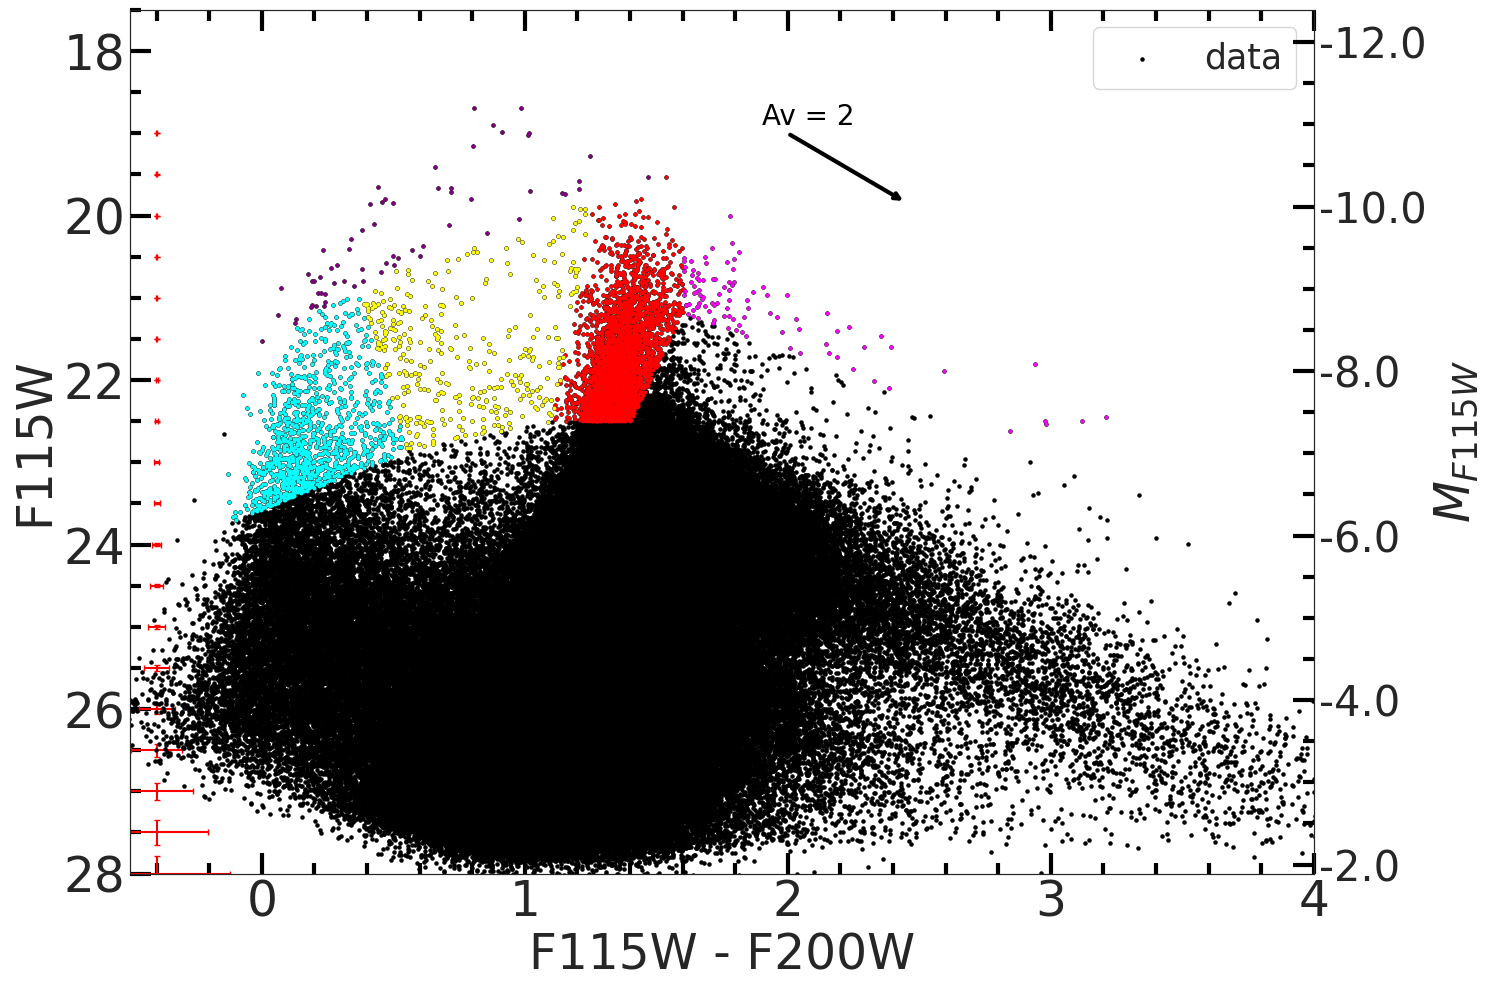

In [39]:
# Change the filename here to change photometry file
tab = Table.read('NGC628_f115w_f150w_f200w_photometry.fits')

gal = 'ngc628' # change the galaxy name here
fig, ax = plt.subplots(figsize=(15,10))
ra_cen  = regions_gal[gal]['ra']
dec_cen = regions_gal[gal]['dec']

filters = {'filt1':'f115w',
           'filt2':'f200w',
           'filt3':'f115w'}

positions = {'ra_col' : 'ra',
             'dec_col': 'dec',
             'ra_cen' : ra_cen,
             'dec_cen': dec_cen}

region = {'r_in':0,
          'r_out': 2000,
          'spatial_filter': 'circle'}

extinction = {'Av'  : regions_gal[gal]['Av'],
              'Av_x': 2,
              'Av_y': 19,
              'Av_' : 2}

axis_limits= {'xlims': [-0.5, 4],
              'ylims': [17.5, 28]}

isochrone_params={'met': [0.02],
                  'label_min': 0,
                  'label_max': 10,
                  'ages': [6.7, 6.8, 7,7.4,7.7, 8]}

error_settings = {'ref_xpos': -0.4,
                  'mag_err_lim':0.2}

plot_settings = {'s':5, 'legend.ncols':2, 'alpha':0.7, 'lw':3}

df_temp = df_cmd_jwst.copy()

df_temp = df_temp[((df_temp['logAge']==6.7) & (df_temp['label']<5)) | (df_temp['logAge']>6.7)]

fig,ax, tab1 = gen_CMD(tab,
                      None,
                      filters,
                      positions,
                      region,
                      extinction,
                      regions_gal[gal]['dismod'],
                      axis_limits,
                      isochrone_params,
                      plot_settings=plot_settings,
                      error_settings=error_settings,
                      other_settings={'ab_dist': True, 'skip_data': False},
                      fig=fig, ax=ax)


x = tab1['mag_vega_F115W'] - tab1['mag_vega_F200W']
y = tab1['mag_vega_F115W']

points = np.column_stack([x, y])

ind_trgb = shapely.contains_xy(trgb_polygon_m51, points)
ind_rsg = shapely.contains_xy(rsg_polygon_m51, points)
ind_rrsg = shapely.contains_xy(rrsg_polygon_m51, points)
ind_ysg = shapely.contains_xy(ysg_polygon_m51, points)
ind_bsg = shapely.contains_xy(bsg_polygon_m51, points)
ind_yms = shapely.contains_xy(yms_polygon_m51, points)

tab_TRGB = tab1[ind_trgb]
tab_RSG  = tab1[ind_rsg]
tab_RRSG = tab1[ind_rrsg]
tab_YSG  = tab1[ind_ysg]
tab_BSG  = tab1[ind_bsg]
tab_YMS  = tab1[ind_yms]

ax.scatter(x[ind_rsg], y[ind_rsg], color='red', s=3, zorder=500)
ax.scatter(x[ind_rrsg], y[ind_rrsg], color='magenta', s=3, zorder=500)
ax.scatter(x[ind_ysg], y[ind_ysg], color='yellow', s=3, zorder=500)
ax.scatter(x[ind_bsg], y[ind_bsg], color='cyan', s=3, zorder=500)
ax.scatter(x[ind_yms], y[ind_yms], color='purple', s=3, zorder=500)

ax.legend(fontsize=25)

# **Step 5: Spatial Distribution of stars in different evolutionary phases**

(np.float64(-520.5790000000001),
 np.float64(12112.458999999999),
 np.float64(-204.39450000000005),
 np.float64(4813.6845))

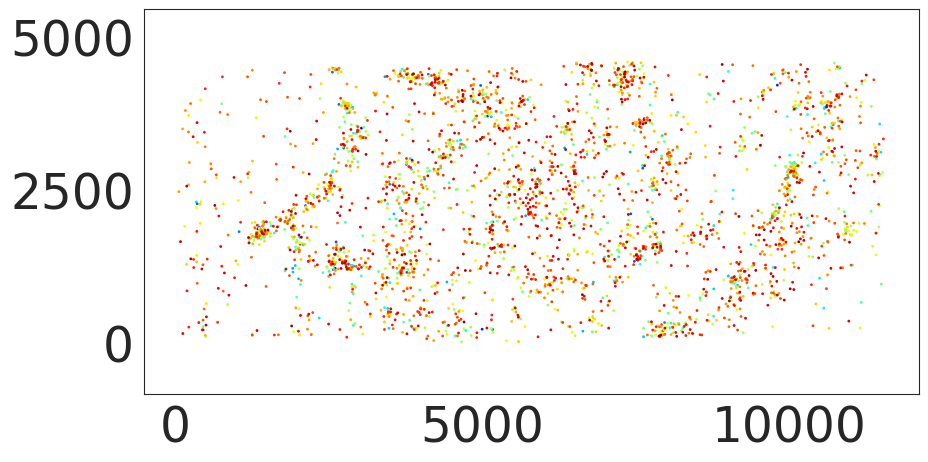

In [40]:
x = tab_RSG['x']
y = tab_RSG['y']
c = tab_RSG['mag_vega_F200W']
plt.figure(figsize=(10,5))
plt.scatter(x,y, s=1, c=c, cmap='jet', )
plt.axis('equal')